In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from functools import reduce
import operator

In [4]:
def create_simple_density_plots(csv_files, methods, y_column='y_rmse', dgp='BF'):
    """
    Simplified version with just density plots
    """
    # Set style
    sns.set_style("darkgrid")
    
    # Create figure
    n_methods = len(methods)
    fig, axes = plt.subplots(n_methods, 1, figsize=(10, 1*n_methods), 
                           sharex=True, gridspec_kw={'hspace': 0.08})
    
    if n_methods == 1:
        axes = [axes]
    
    # Color palette
    palette = sns.color_palette("husl", n_methods)
    
    for idx, (method, file, color) in enumerate(zip(methods, csv_files, palette)):
        try:
            # Load data
            df = pd.read_csv(file)
            data = df[y_column].dropna()
            
            # Create density plot
            ax = axes[idx]
            sns.kdeplot(data=data, ax=ax, color=color, fill=True,
                       alpha=0.5, linewidth=2)
            
            # Add method label on left
            ax.text(-0.1, 0.5, method, transform=ax.transAxes,
                   fontsize=11, fontweight='bold', va='center', ha='right')
            
            # Clean up
            ax.set_ylabel('Density', fontsize=9)
            ax.tick_params(labelsize=8)
            
        except Exception as e:
            print(f"Error processing {method}: {e}")
            axes[idx].set_visible(False)
    
    # Common x-axis label
    axes[-1].set_xlabel(y_column, fontsize=11, fontweight='bold')
    
    # plt.suptitle(f'Density Plots of {y_column}', fontsize=13, fontweight='bold', y=0.98)
    plt.tight_layout()
    plt.savefig(f'figures/simple_density_plots_{dgp}_{y_column}.pdf', dpi=300)
    plt.show()


In [8]:
# # dgp_list = ['BF', 'MB']
# # dgp_list = ['CA']
# dgp_list = ['UE', 'UF', 'MA']
# metrics = ['y_rmse', 'y_bias']

# for dgp in dgp_list:
#     for metric in metrics:
#         # Define methods and file paths
#         methods = ['BBLR', 'LOWESS', 'LPR2', 'LPR3']
#         # csv_files_names = [f'{dgp}_BBLR_0.0_1000_normal_up_to_N_OLS_mean_test.csv',
#         #             f'{dgp}_LOWESS_0.0_1000_normal_test.csv',
#         #             f'{dgp}_LPR2_0.0_1000_normal_test.csv',
#         #             f'{dgp}_LPR3_0.0_1000_normal_test.csv']
#         methods = ['BBLR', 'LOWESS']
#         csv_files_names = [f'{dgp}_BBLR_0.0_1000_normal_up_to_N_OLS_mean_test.csv',
#                     f'{dgp}_LOWESS_0.0_1000_normal_test.csv']
#         csv_files = [f'cluster_results/M100/{name}' for name in csv_files_names]

#         # Create plots
#         create_simple_density_plots(csv_files, methods, y_column=metric, dgp=dgp)

# Grid

In [48]:
colnames_dict = {
    'y_bias': 'bias of $y$',
    'y_rmse': 'RMSE of $y$',
    'B0_bias': 'bias of $\\beta_0$',
    'B0_rmse': 'RMSE of $\\beta_0$',
    'B1_bias': 'bias of $\\beta_1$',
    'B1_rmse': 'RMSE of $\\beta_1$',
    'B2_bias': 'bias of $\\beta_2$',
    'B2_rmse': 'RMSE of $\\beta_2$',
    'B3_bias': 'bias of $\\beta_3$',
    'B3_rmse': 'RMSE of $\\beta_3$',
    'B4_bias': 'bias of $\\beta_4$',
    'B4_rmse': 'RMSE of $\\beta_4$',
}

def create_simple_density_plots(csv_files, methods, y_column='y_rmse', dgp='BF',
                                ax=None, show_xlabel=True, show_title=False):
    """
    Simplified version with just density plots - now supports external axes
    """
    # White background (no grey darkgrid); keep light gridlines for readability.
    sns.set_style("whitegrid")

    # Font sizes (bumped up across the board) — tune in one place.
    LABEL_FS  = 20   # axis labels
    TITLE_FS  = 20   # subplot titles
    LEGEND_FS = 18   # legend
    METHOD_FS = 20   # left-hand method annotation (standalone mode)
    TICK_FS   = 16   # tick labels

    # Create figure only if ax is not provided
    if ax is None:
        n_methods = len(methods)
        fig, axes = plt.subplots(n_methods, 1, figsize=(d*3, 1*n_methods),
                               sharex=True, gridspec_kw={'hspace': 0.08})

        if n_methods == 1:
            axes = [axes]
        standalone = True
    else:
        axes = [ax]
        standalone = False

    # Color palette
    palette = sns.color_palette("husl", len(methods))

    for idx, (method, file, color) in enumerate(zip(methods, csv_files, palette)):
        try:
            df = pd.read_csv(file)
            data = df[y_column].dropna()

            current_ax = axes[idx] if standalone else ax
            sns.kdeplot(data=data, ax=current_ax, color=color, fill=True,
                       alpha=0.5, linewidth=2, label=method)

            # Force a white axes face in case a darkgrid theme is active globally.
            current_ax.set_facecolor('white')

            if standalone:
                current_ax.text(-0.1, 0.5, method, transform=current_ax.transAxes,
                           fontsize=METHOD_FS, fontweight='bold', va='center', ha='right')
            else:
                current_ax.legend(fontsize=LEGEND_FS, loc='upper right')

            current_ax.set_ylabel('Density', fontsize=LABEL_FS)
            current_ax.tick_params(labelsize=TICK_FS)

        except Exception as e:
            print(f"Error processing {method}: {e}")
            if standalone:
                axes[idx].set_visible(False)

    # X-axis label: "RMSE" for the left column, "bias" for the right column.
    if y_column.endswith('rmse'):
        xlabel = 'RMSE'
    elif y_column.endswith('bias'):
        xlabel = 'bias'
    else:
        xlabel = y_column

    target_ax = axes[-1] if standalone else ax
    if show_xlabel:
        target_ax.set_xlabel(xlabel, fontsize=LABEL_FS, fontweight='bold')
    else:
        # kdeplot auto-labels the x-axis with the Series name (e.g. 'B0_rmse');
        # clear it on interior rows so only the bottom row is labelled.
        target_ax.set_xlabel('')

    if standalone:
        plt.tight_layout()
        plt.savefig(f'figures/simple_density_plots_{dgp}_{y_column}.pdf', dpi=300)
        plt.show()
    elif show_title:
        ax.set_title(f'{colnames_dict[y_column]}', fontsize=TITLE_FS, fontweight='bold')

def create_density_grid(dgp, d, methods=['BBLR', 'LOWESS']):
    """
    Creates a (d+1)x2 grid of density plots using different parameters
    """
    csv_files_names = [f'{dgp}_BBLR_0.0_1000_normal_up_to_N_OLS_mean_test.csv',
                f'{dgp}_LOWESS_0.0_1000_normal_test.csv']
    if 'LPR2' in methods:
        csv_files_names = [f'{dgp}_BBLR_0.0_1000_normal_up_to_N_OLS_mean_test.csv',
                    f'{dgp}_LOWESS_0.0_1000_normal_test.csv',
                    f'{dgp}_LPR2_0.0_1000_normal_test.csv']
    csv_files = [f'cluster_results/M1000sigma05/{name}' for name in csv_files_names]  # TODO: repeat for M=1000
    plot_configs_list = [[{'csv_files':csv_files, 'methods':methods, 'y_column':f'B{i+1}_rmse', 'dgp':dgp},
                     {'csv_files':csv_files, 'methods':methods, 'y_column':f'B{i+1}_bias', 'dgp':dgp}] for i in range(d)]
    plot_configs = [item for sublist in plot_configs_list for item in sublist]

    # Create the (d+1)x2 grid
    fig, axes = plt.subplots(d, 2, figsize=(12, 4*d))  # TODO: elastic fig.height
    axes = axes.flatten()
    
    for i, config in enumerate(plot_configs):
        # Determine if this is a bottom row subplot (for x-labels)
        show_xlabel = (i >= d * 2)
        
        # Call your function with the subplot axes
        create_simple_density_plots(
            csv_files=config['csv_files'],
            methods=config['methods'],
            y_column=config['y_column'],
            dgp=config['dgp'],
            ax=axes[i],
            show_xlabel=show_xlabel,
            show_title=True
        )
    
    plt.tight_layout()
    if 'LPR2' in methods:
        plt.savefig(f'figures/density_grid_{dgp}_lpr.pdf', dpi=300, bbox_inches='tight')
    else:
        plt.savefig(f'figures/density_grid_{dgp}.pdf', dpi=300, bbox_inches='tight')
    plt.show()


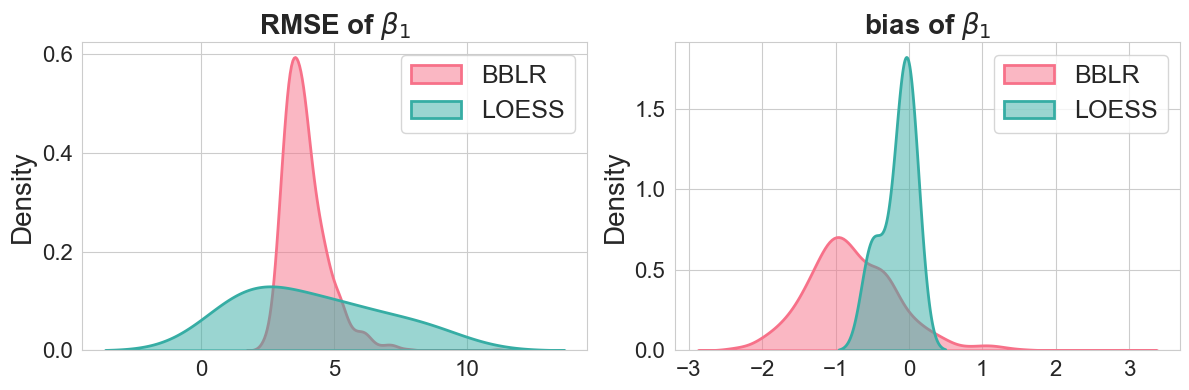

In [56]:
create_density_grid('UF', 1, methods=['BBLR', 'LOESS'])

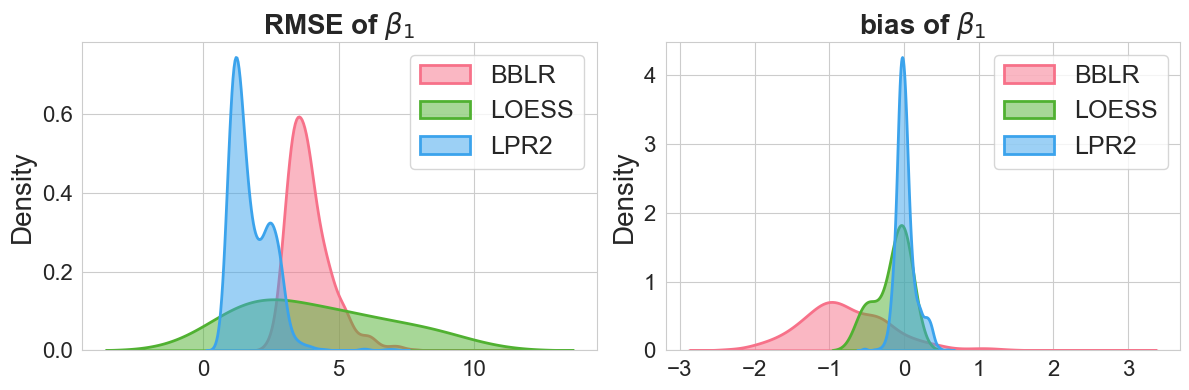

In [57]:
create_density_grid('UF', 1, methods=['BBLR', 'LOESS', 'LPR2'])

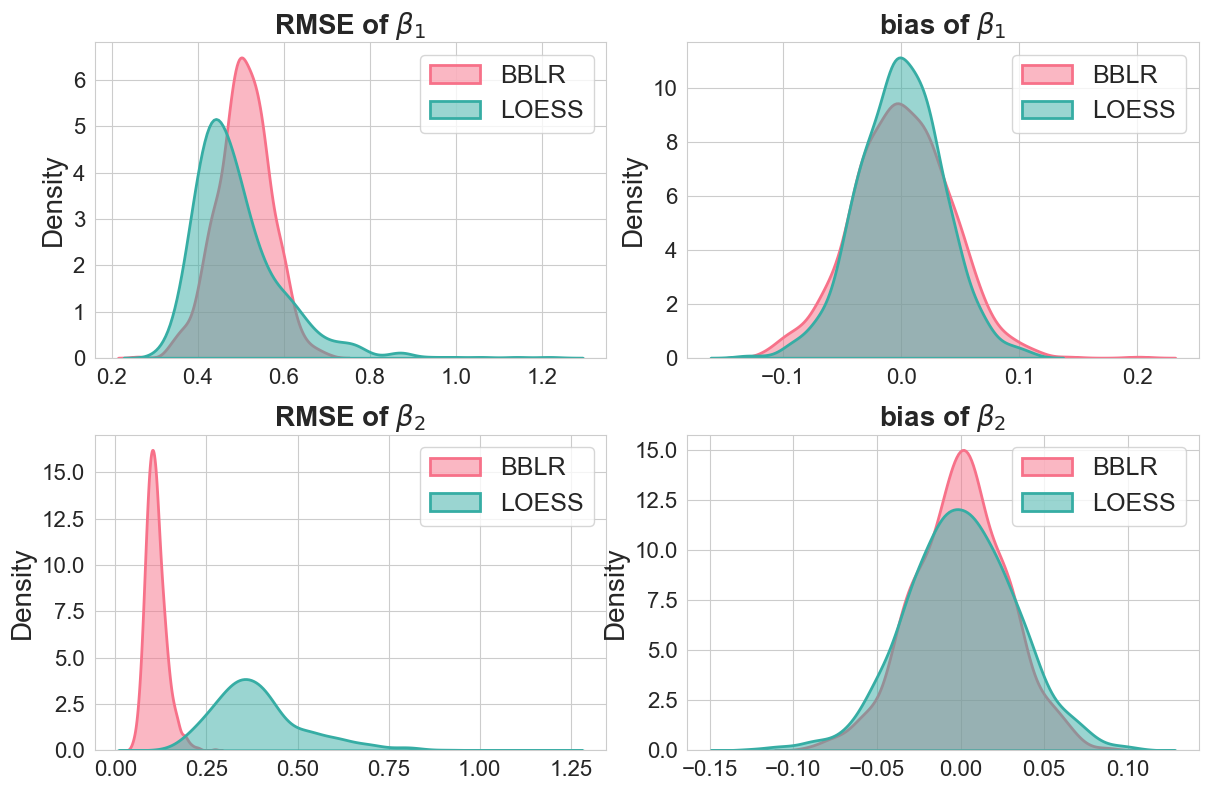

In [58]:
# create_simple_density_plots(csv_files, methods, y_column='y_rmse', dgp='BF', 
#                                 ax=None, show_xlabel=True, show_title=False)

create_density_grid('BF', 2, methods=['BBLR', 'LOESS'])

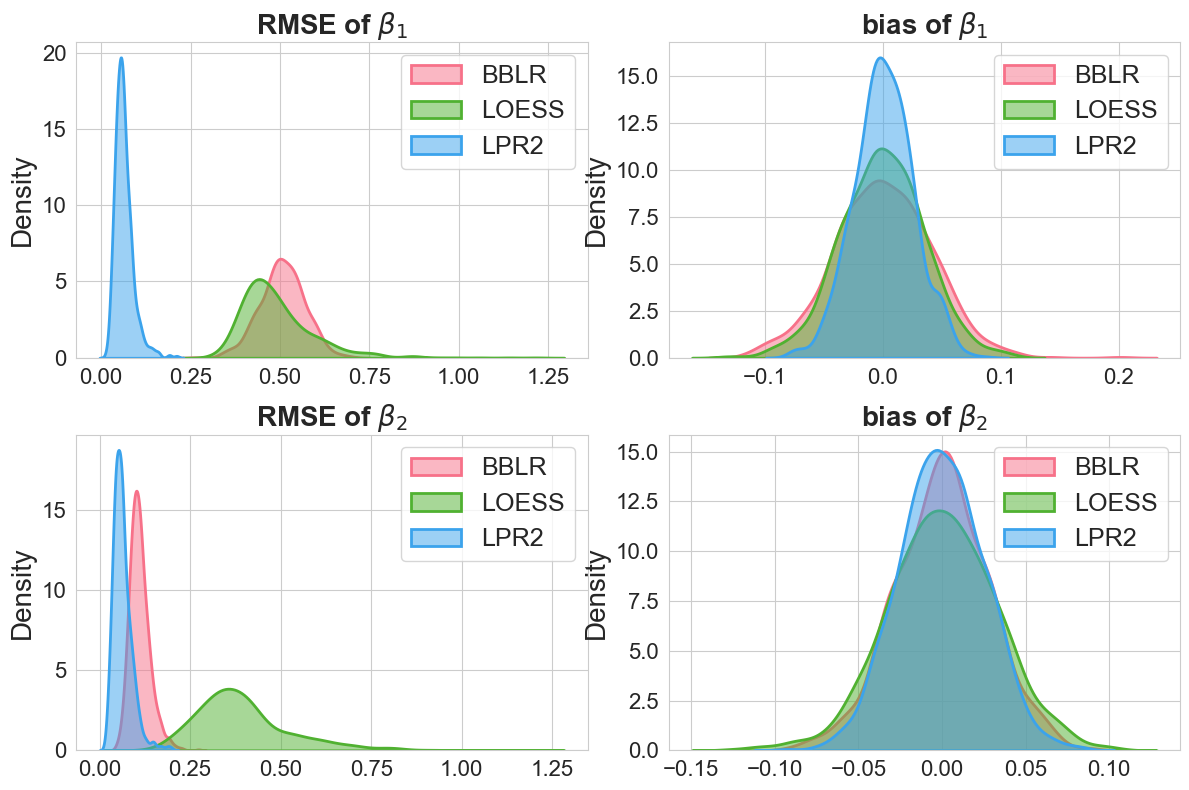

In [60]:
create_density_grid('BF', 2, methods=['BBLR', 'LOESS', 'LPR2'])

# Tables comparing RMSE and bias

In [3]:
def results_table(dgp_list, test_flag, metrics_names, d):
    results_folder_name = 'M1000sigma05'  # M1000
    methods = ['BBLR', 'LOWESS']
    means_rows = []
    features = [f'B{i+1}' for i in range(d)] + ['y']
    metrics = reduce(operator.concat, [[feature + '_' + metric_name for metric_name in metrics_names] for feature in features])
    for dgp in dgp_list:
        # Define methods and file paths
        # csv_files_names = [f'{dgp}_{method}_0.0_1000_normal_up_to_N_OLS_mean_{test_flag}.csv' for method in methods]
        csv_files_names = [f'{dgp}_BBLR_0.0_1000_normal_up_to_N_OLS_mean_{test_flag}.csv',
            f'{dgp}_LOWESS_0.0_1000_normal_{test_flag}.csv']
        csv_files_paths = [f'cluster_results/{results_folder_name}/{name}' for name in csv_files_names]
        means_vectors = []
        for csv_file_path in csv_files_paths:
            results_df = pd.read_csv(csv_file_path)
            for col in metrics:
                if col not in results_df.columns:
                    results_df[col] = np.nan
            results_df_means = results_df[metrics].mean()
            means_vectors.append(results_df_means)
        means_row = reduce(operator.concat, [[means_vector[metric] for means_vector in means_vectors] for metric in metrics])
        means_rows.append(means_row)
    means_rows = np.array(means_rows).round(3)
    cols = []
    for feature in features:
        cols = cols + methods
    return pd.DataFrame(means_rows, index=dgp_list, columns=cols)

In [8]:
def table_to_latex(dgp_list, test_flag, metrics_names, d, methods=['BBLR', 'LOWESS'], table_dir='tables'):
    """
    Runs results_table and writes the result as a LaTeX table to a .txt file.
    In each BBLR/LOWESS pair, the value closer to zero is bolded.
    Returns the (numeric) DataFrame from results_table for further use.
    """
    metric_name = metrics_names[0]
    col_names = [f"$\\beta_{i+1}$" for i in range(d)] + ['$y$']

    df = results_table(dgp_list, test_flag, metrics_names, d)
    df.columns = pd.MultiIndex.from_product([col_names, methods])

    df_latex = df.copy().astype(object)
    for col_name in col_names:
        bblr_vals = df[(col_name, 'BBLR')]
        lowess_vals = df[(col_name, 'LOWESS')]
        bblr_closer = bblr_vals.abs() <= lowess_vals.abs()
        df_latex[(col_name, 'BBLR')] = [
            f"\\textbf{{{v:.3f}}}" if closer else f"{v:.3f}"
            for v, closer in zip(bblr_vals, bblr_closer)
        ]
        df_latex[(col_name, 'LOWESS')] = [
            f"{v:.3f}" if closer else f"\\textbf{{{v:.3f}}}"
            for v, closer in zip(lowess_vals, bblr_closer)
        ]

    metric_display = {'rmse': 'RMSE', 'bias': 'bias'}.get(metric_name, metric_name)
    caption = (f"{metric_display} of BBLR and LOWESS on the {test_flag} set for the "
               f"{dgp_list[0][0]} data generating processes. For each coefficient, the "
               "value closer to zero is shown in bold.")
    label = f"tab:{test_flag}_{metric_name}_table_{dgp_list[0][0].lower()}"

    latex_str = df_latex.to_latex(multicolumn=True, caption=caption, label=label, escape=False)

    table_file_name = f"{table_dir}/table_{metric_name}_{test_flag}_{dgp_list[0][0]}.txt"
    with open(table_file_name, "w") as f:
        f.write(latex_str)

    return df

In [4]:
def results_table_lpr2(dgp_list, test_flag, metrics_names, d):
    results_folder_name = 'M1000sigma05'  # M1000
    methods = ['BBLR', 'LOWESS', 'LPR2']
    means_rows = []
    features = [f'B{i+1}' for i in range(d)] + ['y']
    metrics = reduce(operator.concat, [[feature + '_' + metric_name for metric_name in metrics_names] for feature in features])
    for dgp in dgp_list:
        # Define methods and file paths (LPR2 files follow the same naming pattern as LOWESS)
        csv_files_names = [f'{dgp}_BBLR_0.0_1000_normal_up_to_N_OLS_mean_{test_flag}.csv',
            f'{dgp}_LOWESS_0.0_1000_normal_{test_flag}.csv',
            f'{dgp}_LPR2_0.0_1000_normal_{test_flag}.csv']
        csv_files_paths = [f'cluster_results/{results_folder_name}/{name}' for name in csv_files_names]
        means_vectors = []
        for csv_file_path in csv_files_paths:
            results_df = pd.read_csv(csv_file_path)
            for col in metrics:
                if col not in results_df.columns:
                    results_df[col] = np.nan
            results_df_means = results_df[metrics].mean()
            means_vectors.append(results_df_means)
        means_row = reduce(operator.concat, [[means_vector[metric] for means_vector in means_vectors] for metric in metrics])
        means_rows.append(means_row)
    means_rows = np.array(means_rows).round(3)
    cols = []
    for feature in features:
        cols = cols + methods
    return pd.DataFrame(means_rows, index=dgp_list, columns=cols)

In [9]:
def table_to_latex_lpr2(dgp_list, test_flag, metrics_names, d, methods=['BBLR', 'LOWESS', 'LPR2'], table_dir='tables'):
    """
    Runs results_table_lpr2 and writes the result as a LaTeX table to a .txt file.
    For each coefficient, the value closest to zero among the methods is bolded.
    LOWESS is renamed to LOESS in the LaTeX output.
    Returns the (numeric) DataFrame from results_table_lpr2 for further use.
    """
    metric_name = metrics_names[0]
    col_names = [f"$\\beta_{i+1}$" for i in range(d)] + ['$y$']

    df = results_table_lpr2(dgp_list, test_flag, metrics_names, d)
    df.columns = pd.MultiIndex.from_product([col_names, methods])

    display_names = ['LOESS' if m == 'LOWESS' else m for m in methods]

    df_latex = df.copy().astype(object)
    for col_name in col_names:
        vals_by_method = {m: df[(col_name, m)] for m in methods}
        abs_vals = np.array([vals_by_method[m].abs().to_numpy() for m in methods])
        closest_idx = np.argmin(abs_vals, axis=0)
        for i, m in enumerate(methods):
            df_latex[(col_name, m)] = [
                f"\\textbf{{{v:.3f}}}" if closest_idx[j] == i else f"{v:.3f}"
                for j, v in enumerate(vals_by_method[m])
            ]

    df_latex.columns = pd.MultiIndex.from_product([col_names, display_names])

    metric_display = {'rmse': 'RMSE', 'bias': 'bias'}.get(metric_name, metric_name)
    methods_str = ', '.join(display_names[:-1]) + f', and {display_names[-1]}'
    caption = (f"{metric_display} of {methods_str} on the {test_flag} set for the "
               f"{dgp_list[0][0]} data generating processes. For each coefficient, the "
               "value closest to zero is shown in bold.")
    label = f"tab:{test_flag}_{metric_name}_table_{dgp_list[0][0].lower()}_lpr2"

    latex_str = df_latex.to_latex(multicolumn=True, caption=caption, label=label, escape=False)

    table_file_name = f"{table_dir}/table_{metric_name}_{test_flag}_{dgp_list[0][0]}_lpr2.txt"
    with open(table_file_name, "w") as f:
        f.write(latex_str)

    return df

In [68]:
dgp_list = ['UA', 'UB', 'UE', 'UF']
test_flags = ['test', 'train']
metrics_names = ['rmse', 'bias']
d = 1
methods = ['BBLR', 'LOWESS', 'LPR2']

results_table_lpr2(dgp_list, 'test', ['rmse'], 1)

,BBLR,LOWESS,LPR2,BBLR,LOWESS,LPR2
UA,0.647,0.075,0.076,0.516,0.501,0.502
UB,1.044,0.909,0.076,0.525,0.510,0.502
UE,4.129,4.208,2.400,0.571,0.527,0.531
UF,3.917,4.142,1.734,0.642,0.546,0.593


In [81]:
# dgp_list = ['UA', 'UB', 'UE', 'UF']
# d = 1

dgp_list = ['BA', 'BB', 'BF']
d = 2

test_flag = 'test'
metrics_names = ['rmse']
table_to_latex_lpr2(dgp_list, test_flag, metrics_names, d, methods=['BBLR', 'LOWESS', 'LPR2'], table_dir='tables')

$\beta_1$               $\beta_2$                  $y$              
        BBLR LOWESS   LPR2      BBLR LOWESS   LPR2   BBLR LOWESS   LPR2
BA     0.028  0.038  0.063     0.028  0.038  0.063  0.503  0.502  0.504
BB     0.484  0.597  0.063     0.485  0.599  0.063  0.566  0.541  0.504
BF     0.506  0.492  0.063     0.111  0.394  0.063  0.536  0.530  0.504

In [77]:
lpr2_df = pd.read_csv('cluster_results/M1000sigma05/BB_LPR2_0.0_1000_normal_test.csv')
lpr2_df[['B1_rmse', 'B2_rmse', 'y_rmse']].mean()

B1_rmse    0.063028
B2_rmse    0.062828
y_rmse     0.504072
dtype: float64

In [ ]:
test_flags = ['test', 'train']
metrics_names = ['rmse']
d = 1
methods = ['BBLR', 'LOWESS']
dgp_list = ['MA', 'MB', 'MC', 'MD', 'ME', 'MF', 'MG', 'MH', 'MI', 'MJ', 'MM', 'MN', 'MO', 'MP', 'MQ', 'MR']  # add MS, MT
results_table(dgp_list, 'test', ['rmse'], 4)

,BBLR,LOWESS,BBLR,LOWESS,BBLR,LOWESS,BBLR,LOWESS,BBLR,LOWESS
MA,0.119,0.237,0.113,0.234,0.869,0.595,0.113,0.233,0.633,0.621
MB,1.414,1.385,0.064,0.092,0.067,0.094,0.064,0.091,0.541,0.542
MC,0.445,0.391,0.446,0.390,0.838,0.592,0.130,0.258,0.669,0.650
MD,0.330,0.297,0.299,0.255,0.454,0.368,0.454,0.368,0.601,0.587
ME,0.447,0.405,0.447,0.404,1.009,0.758,0.581,0.550,0.728,0.699
MF,0.512,0.651,3.102,2.294,0.460,0.591,0.208,0.527,1.543,1.206
MG,0.223,0.208,0.393,0.344,0.422,0.326,0.082,0.131,0.558,0.557
MH,0.450,0.432,0.585,0.527,0.931,0.636,0.585,0.528,0.702,0.707
MI,0.523,0.425,0.281,0.242,0.322,0.261,0.094,0.143,0.572,0.566
MJ,1.373,1.161,1.060,0.978,1.389,1.464,3.047,2.263,1.695,1.351


In [ ]:
dgp_list = ['MA', 'MB', 'MC', 'MD', 'ME', 'MF', 'MG', 'MH', 'MI', 'MJ', 'MM', 'MN', 'MO']#, 'MP', 'MQ', 'MR'] 
table_to_latex_lpr2(dgp_list, test_flag, metrics_names, d=4, methods=['BBLR', 'LOWESS', 'LPR2'], table_dir='tables')

$\beta_1$               $\beta_2$               $\beta_3$                \
        BBLR LOWESS   LPR2      BBLR LOWESS   LPR2      BBLR LOWESS   LPR2   
MA     0.119  0.246  0.073     0.113  0.243  0.073     0.869  0.592  0.073   
MB     1.414  1.384  1.395     0.064  0.095  0.101     0.067  0.097  0.101   
MC     0.445  0.396  0.073     0.446  0.395  0.073     0.838  0.590  0.073   
MD     0.330  0.299  0.227     0.299  0.259  0.222     0.454  0.368  0.107   
ME     0.447  0.411  0.167     0.447  0.411  0.166     1.009  0.756  0.535   
MF     0.512  0.672  0.561     3.102  2.274  1.150     0.460  0.614  0.379   
MG     0.223  0.208  0.198     0.393  0.342  0.338     0.422  0.323  0.356   
MH     0.450  0.445  0.143     0.585  0.537  0.521     0.931  0.639  0.141   
MI     0.523  0.421  0.394     0.281  0.243  0.253     0.322  0.261  0.226   
MJ     1.373  1.169  0.633     1.060  0.991  0.579     1.389  1.476  1.416   
MM     0.495  0.460  0.471     0.775  0.620  0.352     0.450  0.376  0.145   
MN     1.364  1.092  0.588     1.049  0.884  0.511     1.381  1.389  1.380   
MO     0.065  0.085  0.073     0.056  0.080  0.073     0.278  0.223  0.073   

   $\beta_4$                  $y$                
        BBLR LOWESS   LPR2   BBLR LOWESS   LPR2  
MA     0.113  0.243  0.073  0.633  0.618  0.512  
MB     0.064  0.094  0.101  0.541  0.540  0.542  
MC     0.130  0.270  0.073  0.669  0.646  0.512  
MD     0.454  0.368  0.107  0.601  0.584  0.534  
ME     0.581  0.554  0.537  0.728  0.693  0.600  
MF     0.208  0.554  0.382  1.543  1.164  0.785  
MG     0.082  0.135  0.132  0.558  0.554  0.555  
MH     0.585  0.537  0.520  0.702  0.702  0.562  
MI     0.094  0.149  0.142  0.572  0.564  0.561  
MJ     3.047  2.247  1.136  1.695  1.310  0.848  
MM     0.118  0.219  0.145  0.658  0.618  0.560  
MN     0.932  0.780  0.457  1.019  0.895  0.688  
MO     0.056  0.079  0.073  0.526  0.523  0.512

In [24]:
# # to do: fix it

# # RMSE ratio BBLR to LR
# dgp_list = ['MA', 'MB', 'MC', 'MD', 'ME', 'MF', 'MG', 'MH', 'MI', 'MJ', 'MM', 'MN', 'MO', 'MP', 'MQ', 'MR']

# test_flag = 'test'  # 'test' or 'train'
# results_folder_name = 'M1000sigma05'  # M1000
# # csv_files_paths_bblr = [f'cluster_results/{results_folder_name}/{dgp}_BBLR_0.0_1000_normal_up_to_N_OLS_mean_test.csv' for dgp in dgp_list]
# # csv_files_paths_lr = [f'cluster_results/{results_folder_name}/{dgp}_LR_0.0_1000_normal_test.csv' for dgp in dgp_list]

# # rmse_ratios = []
# etas = []
# for dgp in dgp_list:
#     bblr_file = f'cluster_results/{results_folder_name}/{dgp}_BBLR_0.0_1000_normal_up_to_N_OLS_mean_test.csv'
#     lr_file = f'cluster_results/{results_folder_name}/{dgp}_LR_0.0_1000_normal_test.csv'
#     bblr_df = pd.read_csv(bblr_file)
#     lr_df = pd.read_csv(lr_file)
#     rmse_bblr = bblr_df['y_rmse'].mean()
#     rmse_lr_value = lr_df['y_rmse'].mean()
#     sigma_hat_bblr = bblr_df['y_sigma_hat'].mean()
#     sigma_hat_lr = lr_df['y_sigma_hat'].mean()
#     eta = (rmse_bblr**2 - sigma_hat_bblr**2) / (rmse_lr_value**2 - sigma_hat_lr**2)
#     etas.append(eta)
#     # rmse_ratio = rmse_bblr / rmse_lr_value if rmse_lr_value != 0 else np.nan
#     # rmse_ratios.append(rmse_ratio)

In [6]:
all_rmse = results_table(dgp_list, 'test', ['rmse'], 4)
# compute mean rmse across all features for each method and dgp
bblr_columns_numbers = [0, 2, 4, 6]
lowess_columns_numbers = [1, 3, 5, 7]
bblr_rmse_means = all_rmse.iloc[:, bblr_columns_numbers].mean(axis=1)
lowess_rmse_means = all_rmse.iloc[:, lowess_columns_numbers].mean(axis=1)

pd.DataFrame({'BBLR': bblr_rmse_means, 'LOWESS': lowess_rmse_means}, index=dgp_list)

,BBLR,LOWESS
MA,0.30350,0.32475
MB,0.40225,0.41550
MC,0.46475,0.40775
MD,0.38425,0.32200
ME,0.62100,0.52925
MF,1.07050,1.01575
MG,0.28000,0.25225
MH,0.63775,0.53075
MI,0.30500,0.26775
MJ,1.71725,1.46650


In [21]:
# metric_name = 'bias'
metric_name = 'rmse'
train_test_flag = 'test'
d=4

# methods = ['B', 'L']

col_names = [f"$\\beta_{i+1}$" for i in range(d)] + ['$y$']
my_df = table_to_latex(dgp_list, train_test_flag, [metric_name], d, methods=methods)

In [22]:
my_df

$\beta_1$        $\beta_2$        $\beta_3$        $\beta_4$           $y$  \
        BBLR LOWESS      BBLR LOWESS      BBLR LOWESS      BBLR LOWESS   BBLR   
MA     0.119  0.237     0.113  0.234     0.869  0.595     0.113  0.233  0.633   
MB     1.414  1.385     0.064  0.092     0.067  0.094     0.064  0.091  0.541   
MC     0.445  0.391     0.446  0.390     0.838  0.592     0.130  0.258  0.669   
MD     0.330  0.297     0.299  0.255     0.454  0.368     0.454  0.368  0.601   
ME     0.447  0.405     0.447  0.404     1.009  0.758     0.581  0.550  0.728   
MF     0.512  0.651     3.102  2.294     0.460  0.591     0.208  0.527  1.543   
MG     0.223  0.208     0.393  0.344     0.422  0.326     0.082  0.131  0.558   
MH     0.450  0.432     0.585  0.527     0.931  0.636     0.585  0.528  0.702   
MI     0.523  0.425     0.281  0.242     0.322  0.261     0.094  0.143  0.572   
MJ     1.373  1.161     1.060  0.978     1.389  1.464     3.047  2.263  1.695   
MM     0.495  0.457     0.775  0.623     0.450  0.373     0.118  0.211  0.658   
MN     1.364  1.096     1.049  0.884     1.381  1.386     0.932  0.778  1.019   
MO     0.065  0.083     0.056  0.077     0.278  0.226     0.056  0.077  0.526   
MP     0.119  0.237     0.113  0.234     0.869  0.595     0.113  0.233  0.633   
MQ     1.716  2.023     1.125  1.244     1.709  1.834     0.939  1.064  1.495   
MR     0.534  0.531     0.156  0.152     0.368  0.365     0.044  0.061  0.508   

           
   LOWESS  
MA  0.621  
MB  0.542  
MC  0.650  
MD  0.587  
ME  0.699  
MF  1.206  
MG  0.557  
MH  0.707  
MI  0.566  
MJ  1.351  
MM  0.624  
MN  0.909  
MO  0.525  
MP  0.621  
MQ  1.499  
MR  0.509

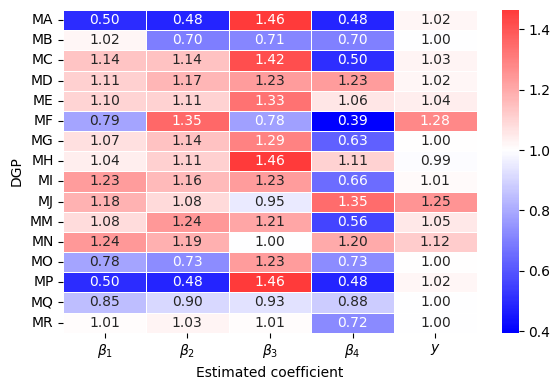

In [23]:
# --- Compute ratios: col[i] / col[i+1] for i in 0, 2, 4, 6, 8, 10 ---
ratio_df = pd.concat(
    [my_df.iloc[:, i] / my_df.iloc[:, i + 1] for i in range(0, 10, 2)],
    axis=1
)

# ratio_df['bblr_lr'] = rmse_ratios
# col_names += ['$\\eta$']

# --- Plot heatmap ---
fig, ax = plt.subplots(figsize=(6, 4))

sns.heatmap(
    ratio_df,
    ax=ax,
    annot=True,
    fmt=".2f",
    cmap="bwr",
    center=1.0,
    linewidths=0.5,
    linecolor="white",
    xticklabels=col_names,
    yticklabels=my_df.index,
    # cbar_kws={"label": "Ratio (odd / even column)"},
)

# ax.set_title("Heatmap of Column Ratios", fontsize=14, fontweight="bold")
ax.set_ylabel("DGP")
ax.set_xlabel("Estimated coefficient")

plt.tight_layout()
plt.savefig(f'figures/heatmap_ratios_{train_test_flag}_{metric_name}_{dgp_list[0][0]}.pdf', dpi=300, bbox_inches='tight')
plt.show()

In [20]:
ratio_df

,0,1,2,3,4
MA,0.502110,0.482906,1.460504,0.484979,1.019324
MB,1.020939,0.695652,0.712766,0.703297,0.998155
MC,1.138107,1.143590,1.415541,0.503876,1.029231
MD,1.111111,1.172549,1.233696,1.233696,1.023850
ME,1.103704,1.106436,1.331135,1.056364,1.041488
MF,0.786482,1.352223,0.778342,0.394687,1.279436
MG,1.072115,1.142442,1.294479,0.625954,1.001795
MH,1.041667,1.110057,1.463836,1.107955,0.992928
MI,1.230588,1.161157,1.233716,0.657343,1.010601
MJ,1.182601,1.083845,0.948770,1.346443,1.254626


In [24]:
metric_name = 'bias'
# metric_name = 'rmse'
train_test_flag = 'test'
d=4

# methods = ['B', 'L']

col_names = [f"$\\beta_{i+1}$" for i in range(d)] + ['$y$']
my_df = table_to_latex(dgp_list, train_test_flag, [metric_name], d, methods=methods)

In [26]:
diff_df = pd.concat(
    [np.abs(my_df.iloc[:, i]) - np.abs(my_df.iloc[:, i + 1]) for i in range(0, 10, 2)],
    axis=1
)

In [27]:
diff_df

,0,1,2,3,4
MA,0.000,0.000,0.000,-0.001,-0.095
MB,0.000,0.000,0.000,0.000,-0.069
MC,0.000,-0.001,-0.001,0.001,-0.088
MD,0.020,0.001,0.000,-0.001,-0.056
ME,0.000,0.000,0.000,0.001,-0.085
MF,-0.001,0.279,-0.001,-0.001,-0.033
MG,0.007,0.000,0.000,0.000,-0.063
MH,0.000,0.001,0.000,0.001,-0.152
MI,0.010,0.010,0.001,-0.001,0.000
MJ,-0.001,0.104,-0.001,0.294,-0.024


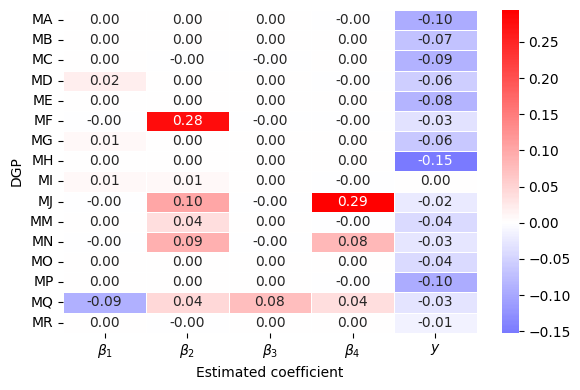

In [29]:
# --- Compute diffs of abs: col[i] - col[i+1] for i in 0, 2, 4, 6, 8, 10 ---
diff_df = pd.concat(
    [np.abs(my_df.iloc[:, i]) - np.abs(my_df.iloc[:, i + 1]) for i in range(0, 10, 2)],
    axis=1
)

# --- Plot heatmap ---
fig, ax = plt.subplots(figsize=(6, 4))

sns.heatmap(
    diff_df,
    ax=ax,
    annot=True,
    fmt=".2f",
    cmap="bwr",
    center=0.0,
    linewidths=0.5,
    linecolor="white",
    xticklabels=col_names,
    yticklabels=my_df.index,
    # cbar_kws={"label": "Ratio (odd / even column)"},
)

# ax.set_title("Heatmap of Column Ratios", fontsize=14, fontweight="bold")
ax.set_ylabel("DGP")
ax.set_xlabel("Estimated coefficient")

plt.tight_layout()
plt.savefig(f'figures/heatmap_ratios_{train_test_flag}_{metric_name}_{dgp_list[0][0]}.pdf', dpi=300, bbox_inches='tight')
plt.show()

In [24]:
# check wmean:

def results_table_wmean(dgp_list, test_flag, metrics_names, d):
    results_folder_name = 'M1000sigma05'  # M1000
    methods = ['BBLR', 'LOWESS', 'BBLRw']
    means_rows = []
    features = [f'B{i}' for i in range(d + 1)] + ['y']
    metrics = reduce(operator.concat, [[feature + '_' + metric_name for metric_name in metrics_names] for feature in features])
    for dgp in dgp_list:
        # Define methods and file paths
        # csv_files_names = [f'{dgp}_{method}_0.0_1000_normal_up_to_N_OLS_mean_{test_flag}.csv' for method in methods]
        csv_files_names = [f'{dgp}_BBLR_0.0_1000_normal_up_to_N_OLS_mean_{test_flag}.csv',
            f'{dgp}_LOWESS_0.0_1000_normal_{test_flag}.csv']
        csv_files_paths = [f'cluster_results/{results_folder_name}/{name}' for name in csv_files_names]
        csv_files_paths.append(f'cluster_results/M100sigma05/{dgp}_BBLR_0.0_1000_normal_up_to_N_OLS_wmean_{test_flag}.csv')
        means_vectors = []
        for csv_file_path in csv_files_paths:
            results_df = pd.read_csv(csv_file_path)
            for col in metrics:
                if col not in results_df.columns:
                    results_df[col] = np.nan
            results_df_means = results_df[metrics].mean()
            means_vectors.append(results_df_means)
        means_row = reduce(operator.concat, [[means_vector[metric] for means_vector in means_vectors] for metric in metrics])
        means_rows.append(means_row)
    means_rows = np.array(means_rows).round(3)
    cols = []
    for feature in features:
        cols = cols + methods
    return pd.DataFrame(means_rows, index=dgp_list, columns=cols)


metric_name = 'rmse'
train_test_flag = 'test'
d = 4
dgp_list = ['MA', 'MB', 'MF', 'MJ']
methods = ['BBLR', 'LOWESS', 'BBLRw']


col_names = [f"$\\beta_{i}$" for i in range(d+1)] + ['$y$']
my_df = results_table_wmean(dgp_list, train_test_flag, [metric_name], d)
my_df.columns = pd.MultiIndex.from_product([col_names, methods])

my_df

$\beta_0$               $\beta_1$               $\beta_2$                \
        BBLR LOWESS  BBLRw      BBLR LOWESS  BBLRw      BBLR LOWESS  BBLRw   
MA     1.421  1.635  1.445     0.119  0.246  0.152     0.113  0.243  0.143   
MB     2.466  2.473  2.485     1.414  1.384  1.428     0.064  0.095  0.080   
MF     2.111  3.384  2.584     0.512  0.672  0.554     3.102  2.274  2.874   
MJ     2.325  3.725  2.868     1.373  1.169  1.306     1.060  0.991  1.015   

   $\beta_3$               $\beta_4$                  $y$                
        BBLR LOWESS  BBLRw      BBLR LOWESS  BBLRw   BBLR LOWESS  BBLRw  
MA     0.869  0.592  0.806     0.113  0.243  0.146  0.633  0.618  0.623  
MB     0.067  0.097  0.087     0.064  0.094  0.081  0.541  0.540  0.544  
MF     0.460  0.614  0.493     0.208  0.554  0.316  1.543  1.164  1.373  
MJ     1.389  1.476  1.337     3.047  2.247  2.848  1.695  1.310  1.547